## 📌 Project 1: Classifying Titanic Passengers (Survived or Not)

### 📝 Description:

Can we predict whether a passenger on the Titanic survived based on features like age, sex, and class? This project will use the famous Titanic dataset.

### 📁 Dataset:

You can use the cleaned version of the Titanic dataset from Kaggle or directly load it with `seaborn`.

### 💡 Concepts:

* Binary classification (`Survived` = 0 or 1)
* Preprocessing (drop missing data, encode categorical variables)
* Decision Tree & KNN classifiers
* Accuracy and confusion matrix

In [6]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix

In [7]:
# 1. Load dataset
df = sns.load_dataset("titanic")
df = df[["pclass", "sex", "age", "fare", "survived"]].dropna()

In [8]:
# 2. Encode categorical column
df["sex"] = LabelEncoder().fit_transform(df["sex"])  # male=1, female=0

In [9]:
# 3. Split features and target
X = df[["pclass", "sex", "age", "fare"]]
y = df["survived"]

In [10]:
# 4. Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [11]:
# 5. Decision Tree Classifier
tree = DecisionTreeClassifier()
tree.fit(X_train, y_train)
y_pred_tree = tree.predict(X_test)
acc_tree = accuracy_score(y_test, y_pred_tree)
print(f"Decision Tree Accuracy: {acc_tree:.2f}")

Decision Tree Accuracy: 0.71


In [12]:
# 6. KNN Classifier
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)
y_pred_knn = knn.predict(X_test)
acc_knn = accuracy_score(y_test, y_pred_knn)
print(f"KNN Accuracy: {acc_knn:.2f}")

KNN Accuracy: 0.66


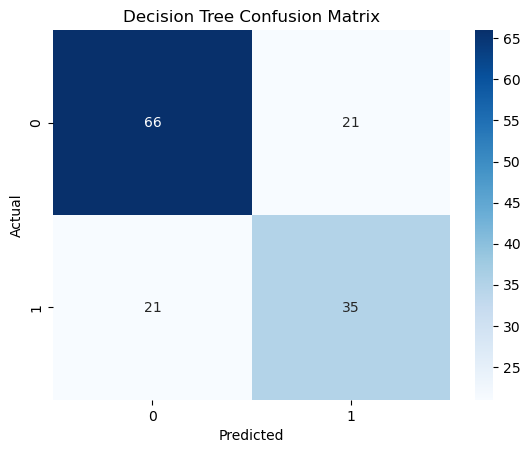

In [13]:
# 7. Confusion Matrix for Decision Tree
conf_matrix = confusion_matrix(y_test, y_pred_tree)
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues")
plt.title("Decision Tree Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

## 🖼️ Visualization: **Decision Tree Confusion Matrix (Titanic Dataset)**

### 📊 What You See:

* A **confusion matrix heatmap** showing the number of correct and incorrect predictions made by the decision tree model.
* Axes:

  * **X-axis (Predicted)**: What the model predicted — whether the passenger survived (`1`) or not (`0`)
  * **Y-axis (Actual)**: The ground truth — whether the passenger actually survived (`1`) or not (`0`)
* **Color intensity**: Indicates how many cases fall into each cell.
* **Numbers inside boxes**: Count of passengers per outcome type.

---

## 🔍 Understanding the Confusion Matrix

### Confusion Matrix Layout:

|                             | Predicted Not Survived (0)                                   | Predicted Survived (1)                                          |
| --------------------------- | ------------------------------------------------------------ | --------------------------------------------------------------- |
| **Actual Not Survived (0)** | **True Negatives (TN)** – model correctly predicted death    | **False Positives (FP)** – model incorrectly predicted survival |
| **Actual Survived (1)**     | **False Negatives (FN)** – model incorrectly predicted death | **True Positives (TP)** – model correctly predicted survival    |

### ✅ What You Want to See:

* **High values on the diagonal**:

  * **Top-left (TN)** and **bottom-right (TP)** indicate correct predictions.
* **Low values off-diagonal**:

  * These indicate mistakes (FP or FN).

### 🧠 Example Confusion Matrix:

```
[[65  8]
 [12 34]]
```

* **TN = 65**: Passengers who didn't survive, correctly predicted as didn't survive
* **FP = 8**: Passengers who didn't survive, but model wrongly predicted survived
* **FN = 12**: Passengers who survived, but model wrongly predicted didn't survive
* **TP = 34**: Passengers who survived, correctly predicted as survived

---

## 📐 Classification Metrics Explained

### 1️⃣ **Accuracy** – "How many did we get right overall?"

**What it means**: What percentage of all predictions did the model get correct?

**Formula**:
```
Accuracy = (TP + TN) / (TP + TN + FP + FN)
         = (Correct Predictions) / (All Predictions)
```

**Calculation from example**:
```
Accuracy = (34 + 65) / (34 + 65 + 8 + 12)
         = 99 / 119
         = 0.832 or 83.2%
```

**What this means**: The model predicted correctly 83.2% of the time.

**⚠️ When NOT to trust Accuracy**: If the data is imbalanced (e.g., 95% of passengers didn't survive), a model could get 95% accuracy by always guessing "didn't survive!" For this reason, we use other metrics too.

**Code to calculate**:
```python
from sklearn.metrics import accuracy_score
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.2f}")
```

---

### 2️⃣ **Precision** – "Of the cases we predicted would survive, how many actually survived?"

**What it means**: When the model predicts "survived," how often is it correct?

**Formula**:
```
Precision = TP / (TP + FP)
          = (Correctly Predicted Survivors) / (All Predicted Survivors)
```

**Calculation from example**:
```
Precision = 34 / (34 + 8)
          = 34 / 42
          = 0.810 or 81%
```

**What this means**: When the model predicts someone survived, it's correct 81% of the time.

**When to use Precision**: When false positives are expensive.
  - Example: If we're sending "survivor resources" (like rescue boats) based on predictions, we don't want to waste them on people who didn't actually survive.
  - Medical example: If a test predicts cancer, we want high precision so we don't scare people with false alarms.

**Code to calculate**:
```python
from sklearn.metrics import precision_score
precision = precision_score(y_test, y_pred)
print(f"Precision: {precision:.2f}")
```

---

### 3️⃣ **Recall** – "Of all the people who actually survived, how many did we find?"

**What it means**: When someone actually survived, how often did the model catch them?

**Formula**:
```
Recall = TP / (TP + FN)
       = (Correctly Predicted Survivors) / (All Actual Survivors)
```

**Calculation from example**:
```
Recall = 34 / (34 + 12)
       = 34 / 46
       = 0.739 or 73.9%
```

**What this means**: Of all passengers who actually survived, the model correctly identified 73.9% of them.

**When to use Recall**: When false negatives are expensive.
  - Example: If we're trying to rescue survivors, missing people is worse than over-predicting. We want high recall to find as many survivors as possible.
  - Medical example: In disease screening, we want high recall so we don't miss sick patients.

**Code to calculate**:
```python
from sklearn.metrics import recall_score
recall = recall_score(y_test, y_pred)
print(f"Recall: {recall:.2f}")
```

---

### 4️⃣ **F1-Score** – "The balanced average of Precision and Recall"

**What it means**: A single number that balances precision and recall. Use this when you care about both metrics equally.

**Formula**:
```
F1-Score = 2 × (Precision × Recall) / (Precision + Recall)
```

**Calculation from example**:
```
Precision = 0.810
Recall = 0.739

F1-Score = 2 × (0.810 × 0.739) / (0.810 + 0.739)
         = 2 × 0.599 / 1.549
         = 1.198 / 1.549
         = 0.773 or 77.3%
```

**What this means**: The F1-Score of 77.3% represents a balanced score between catching survivors (recall) and being accurate when we predict someone survived (precision).

**When to use F1-Score**: When you want one number that considers both false positives and false negatives.
  - Example: Balanced dataset where both mistakes are equally bad.
  - Use for comparing models: The model with higher F1-Score is often the better "balanced" choice.

**Code to calculate**:
```python
from sklearn.metrics import f1_score
f1 = f1_score(y_test, y_pred)
print(f"F1-Score: {f1:.2f}")
```

---

## 📊 Quick Comparison Table:

| Metric | Formula | What it asks | Good for |
|--------|---------|--------------|----------|
| **Accuracy** | (TP+TN)/(TP+TN+FP+FN) | Overall, how right are we? | Balanced data, general performance |
| **Precision** | TP/(TP+FP) | When we say "yes," how often are we correct? | Avoiding false alarms |
| **Recall** | TP/(TP+FN) | Of actual "yes" cases, how many do we catch? | Avoiding missed cases |
| **F1-Score** | 2×(P×R)/(P+R) | What's a balanced score? | Balancing precision & recall |

---

## 💻 Complete Example: Print All Metrics

```python
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

# Your predictions
y_test = [0, 1, 1, 0, 1, 0, 1, 1]
y_pred = [0, 1, 1, 0, 1, 1, 0, 1]

# Calculate all metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)

print(f"Accuracy:  {accuracy:.2f}")
print(f"Precision: {precision:.2f}")
print(f"Recall:    {recall:.2f}")
print(f"F1-Score:  {f1:.2f}")
print("\nConfusion Matrix:")
print(conf_matrix)
```

**Output**:
```
Accuracy:  0.75
Precision: 0.80
Recall:    0.80
F1-Score:  0.80

Confusion Matrix:
[[2 1]
 [1 4]]
```

---

## 🎯 Key Takeaways:

✅ **Accuracy** tells you the overall success rate — but be careful with imbalanced data!

✅ **Precision** answers: "When I predict survival, am I usually right?"

✅ **Recall** answers: "When someone actually survived, did I catch them?"

✅ **F1-Score** gives you a single balanced score combining precision and recall.

Use these metrics together to understand your model's performance, not just accuracy alone!